In [ ]:
#Arslan Ahmed - XLNET Model code

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from transformers import XLNetTokenizer, TFXLNetForSequenceClassification
from sklearn.preprocessing import LabelEncoder


In [ ]:
def load_data(file_path):
    return pd.read_csv(file_path, delimiter=';', header=None, names=['text', 'label'])

train_data = load_data('/content/train.txt')
val_data = load_data('/content/val.txt')
test_data = load_data('/content/test.txt')

# Example: Convert labels to numerical if they are categorical
label_encoder = LabelEncoder()
train_data['label'] = label_encoder.fit_transform(train_data['label'])
val_data['label'] = label_encoder.transform(val_data['label'])
test_data['label'] = label_encoder.transform(test_data['label'])


In [ ]:
# Print the classes and their corresponding integers
label_mapping = dict(zip(label_encoder.classes_, range(len(label_encoder.classes_))))
print("Label mapping:", label_mapping)

Label mapping: {'anger': 0, 'fear': 1, 'joy': 2, 'love': 3, 'sadness': 4, 'surprise': 5}


In [ ]:
from transformers import XLNetTokenizer
import tensorflow as tf

tokenizer = XLNetTokenizer.from_pretrained('xlnet-base-cased')

def tokenize_and_encode(sentences, max_len=128):
    input_ids = []
    attention_masks = []

    for sent in sentences:
        encoded_dict = tokenizer.encode_plus(
            sent,                            # Sentence to encode.
            add_special_tokens=True,          # Add '[CLS]' and '[SEP]'
            max_length=max_len,               # Pad or truncate.
            pad_to_max_length=True,
            return_attention_mask=True,       # Include attention masks.
            return_tensors='tf'               # Return TensorFlow tensors.
        )
        input_ids.append(encoded_dict['input_ids'])
        attention_masks.append(encoded_dict['attention_mask'])

    return tf.concat(input_ids, axis=0), tf.concat(attention_masks, axis=0)

# Apply tokenization to each dataset
train_inputs, train_masks = tokenize_and_encode(train_data['text'].tolist())
val_inputs, val_masks = tokenize_and_encode(val_data['text'].tolist())
test_inputs, test_masks = tokenize_and_encode(test_data['text'].tolist())

# Convert label series to numpy array
train_labels = train_data['label'].values
val_labels = val_data['label'].values
test_labels = test_data['label'].values

# Create TensorFlow datasets
train_dataset = tf.data.Dataset.from_tensor_slices(({'input_ids': train_inputs, 'attention_mask': train_masks}, train_labels)).shuffle(10000).batch(32)
val_dataset = tf.data.Dataset.from_tensor_slices(({'input_ids': val_inputs, 'attention_mask': val_masks}, val_labels)).batch(32)


/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:89: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


spiece.model:   0%|          | 0.00/798k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.38M [00:00<?, ?B/s]

/usr/local/lib/python3.10/dist-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


config.json:   0%|          | 0.00/760 [00:00<?, ?B/s]

Truncation was not explicitly activated but `max_length` is provided a specific value, please use `truncation=True` to explicitly truncate examples to max length. Defaulting to 'longest_first' truncation strategy. If you encode pairs of sequences (GLUE-style) with the tokenizer you can select this strategy more precisely by providing a specific strategy to `truncation`.
/usr/local/lib/python3.10/dist-packages/transformers/tokenization_utils_base.py:2699: FutureWarning: The `pad_to_max_length` argument is deprecated and will be removed in a future version, use `padding=True` or `padding='longest'` to pad to the longest sequence in the batch, or use `padding='max_length'` to pad to a max length. In this case, you can give a specific length with `max_length` (e.g. `max_length=45`) or leave max_length to None to pad to the maximal input size of the model (e.g. 512 for Bert).
  warnings.warn(


In [ ]:
from transformers import TFXLNetForSequenceClassification

# Load the XLNet model configured for sequence classification
model = TFXLNetForSequenceClassification.from_pretrained('xlnet-base-cased', num_labels=len(set(train_labels)))

optimizer = tf.keras.optimizers.Adam(learning_rate=2e-5)
loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
metric = tf.keras.metrics.SparseCategoricalAccuracy('accuracy')

model.compile(optimizer=optimizer, loss=loss, metrics=[metric])


tf_model.h5:   0%|          | 0.00/565M [00:00<?, ?B/s]

/usr/local/lib/python3.10/dist-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer TruncatedNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(
Some layers from the model checkpoint at xlnet-base-cased were not used when initializing TFXLNetForSequenceClassification: ['lm_loss']
- This IS expected if you are initializing TFXLNetForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFXLNetForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a Be

In [ ]:
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=5
)


Epoch 1/5


Cause: for/else statement not yet supported
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


Cause: for/else statement not yet supported
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert


500/500 [==============================] - 642s 1s/step - loss: 0.6475 - accuracy: 0.7688 - val_loss: 0.2340 - val_accuracy: 0.9135
Epoch 2/5
500/500 [==============================] - 536s 1s/step - loss: 0.2001 - accuracy: 0.9233 - val_loss: 0.1769 - val_accuracy: 0.9300
Epoch 3/5
500/500 [==============================] - 536s 1s/step - loss: 0.1342 - accuracy: 0.9412 - val_loss: 0.1442 - val_accuracy: 0.9375
Epoch 4/5
500/500 [==============================] - 533s 1s/step - loss: 0.1083 - accuracy: 0.9493 - val_loss: 0.1368 - val_accuracy: 0.9425
Epoch 5/5
500/500 [==============================] - 532s 1s/step - loss: 0.0912 - accuracy: 0.9568 - val_loss: 0.1316 - val_accuracy: 0.9410


In [ ]:
model.summary()

Model: "tfxl_net_for_sequence_classification"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 transformer (TFXLNetMainLa  multiple                  116718336 
 yer)                                                            
                                                                 
 sequence_summary (TFSequen  multiple                  590592    
 ceSummary)                                                      
                                                                 
 logits_proj (Dense)         multiple                  4614      
                                                                 
Total params: 117313542 (447.52 MB)
Trainable params: 117313542 (447.52 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
model.save_pretrained('/content/drive/MyDrive/xlnet updated/xlnet_model1')
tokenizer.save_pretrained('/content/drive/MyDrive/xlnet updated/xlnet_model1')


('/content/drive/MyDrive/xlnet updated/xlnet_model1/tokenizer_config.json',
 '/content/drive/MyDrive/xlnet updated/xlnet_model1/special_tokens_map.json',
 '/content/drive/MyDrive/xlnet updated/xlnet_model1/spiece.model',
 '/content/drive/MyDrive/xlnet updated/xlnet_model1/added_tokens.json')

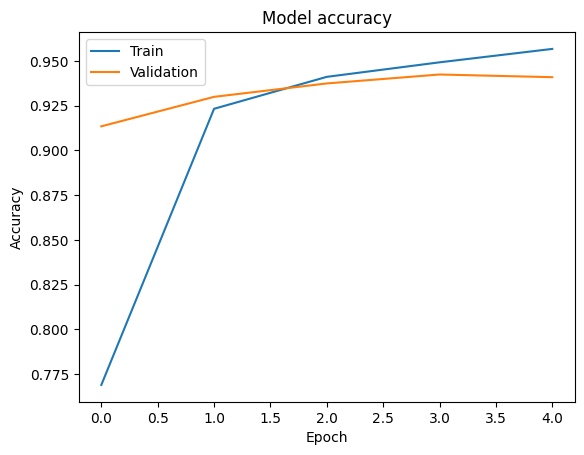

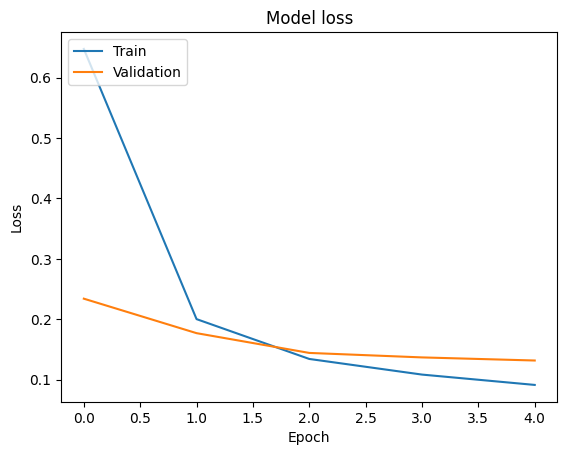

In [ ]:
import matplotlib.pyplot as plt

# Plot training & validation accuracy values
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

# Plot training & validation loss values
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()


In [ ]:
# Model summary
model.summary()

In [ ]:
# Predict classes
y_pred = model.predict(test_dataset)
y_pred_labels = np.argmax(y_pred.logits, axis=1)

# True labels
y_true = test_labels

In [ ]:
# Calculate F1 score, accuracy, and other metrics
accuracy = accuracy_score(y_true, y_pred_labels)
f1 = f1_score(y_true, y_pred_labels, average='weighted')

print(f"Accuracy: {accuracy}")
print(f"F1 Score: {f1}")


In [ ]:
# Classification report
print(classification_report(y_true, y_pred_labels, target_names=label_encoder.classes_))
# Confusion matrix
conf_matrix = confusion_matrix(y_true, y_pred_labels)

# Plot confusion matrix
plt.figure(figsize=(10, 7))
sns.heatmap(conf_matrix, annot=True, fmt='g', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix')
plt.show()